In [2]:
%pip install numpy==1.26.4
%pip install pgmpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
label-studio 1.20.0 requires numpy<2.0.0,>=1.26.4, but you have numpy 2.4.6 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


**Что значат переменные, которые вошли в модель:**

| Переменная | Смысл |
|---|---|
| `dataset` | клиника, где собраны данные | 
| `age` | возраст | 
| `sex` | пол | 
| `cp` | тип боли в груди |
| `thalch` | максимальный пульс на пробе | 
| `exang` | стенокардия, вызванная нагрузкой |
| `oldpeak` | депрессия сегмента ST на нагрузке | 
| `target` | болезнь сердца: `num>0` |

In [3]:
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination
from scipy.stats import chi2_contingency

In [11]:
df = pd.read_csv("heart_disease_uci.csv")
display(df.shape)
display(df.head())
display(df.dtypes)
print("Пациенты по клиникам:")
display(df.dataset.value_counts())

display(f"Полных дубликатов: {df.duplicated().sum()}")
display(f"Распределение таргета num: ", df.num.value_counts().sort_index())

(920, 16)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object

Пациенты по клиникам:


dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

'Полных дубликатов: 0'

'Распределение таргета num: '

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

**Вывод** 920 уникальных пациентов и 16 признаков, среди которых есть как числовые, так и категориальные. `num` принимает значение от 0 до 4, но по факту значения от 1 до 4 - человек болен. То есть распределение примерно равное так как в num = 0 - 411 пациентов, а в num = 1, 2, 3 - 509.

In [21]:
print("chol = 0 по клиникам: ")
display((df.chol == 0).groupby(df.dataset).sum())
print('oldpeak < 0:', (df.oldpeak < 0).sum(), '| по клиникам:', df.loc[df.oldpeak < 0, 'dataset'].value_counts())

print("trestbps = 0 по клиникам")
display((df.trestbps == 0).groupby(df.dataset).sum())

df["chol"] = df["chol"].replace(0, np.nan)
df["trestbps"] = df["trestbps"].replace(0, np.nan)
df["oldpeak"] = df["oldpeak"].replace(0, np.nan)

chol = 0 по клиникам: 


dataset
Cleveland        0
Hungary          0
Switzerland      0
VA Long Beach    0
Name: chol, dtype: int64

oldpeak < 0: 12 | по клиникам: dataset
Switzerland      11
VA Long Beach     1
Name: count, dtype: int64
trestbps = 0 по клиникам


dataset
Cleveland        0
Hungary          0
Switzerland      0
VA Long Beach    0
Name: trestbps, dtype: int64

**Что видно:** нули в `chol` — это не измерения, а замена пропусков (Switzerland: все 123 строки). Отрицательный `oldpeak` (12 строк) почти целиком из Switzerland.

dataset   Cleveland  Hungary  Switzerland  VA Long Beach  кол-во пропусков
age               0        0            0              0                 0
sex               0        0            0              0                 0
dataset           0        0            0              0                 0
cp                0        0            0              0                 0
trestbps          0        0            1             28                 6
chol              0        7          100             28                21
fbs               0        2           60              3                 9
restecg           0        0            0              0                 0
thalch            0        0            0             26                 5
exang             0        0            0             26                 5
oldpeak          32       64           39             48                46
slope             0       64           13             51                33
ca                1      

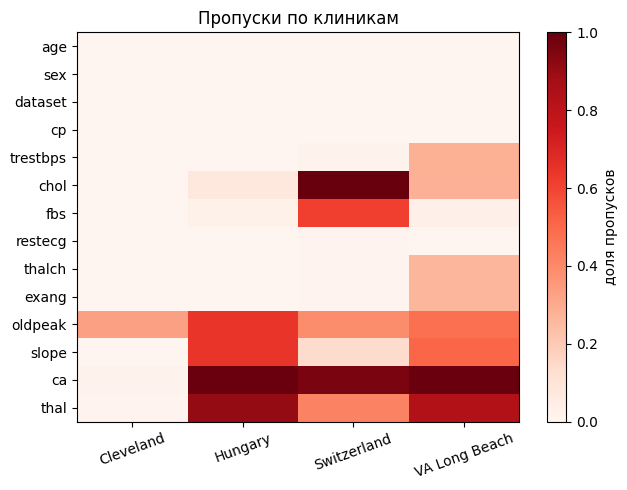

In [23]:
cols = [c for c in df.columns if c not in ["id", "num"]]
miss = df[cols].isna().groupby(df.dataset).mean().T
miss["кол-во пропусков"] = df[cols].isna().mean()
print((100 * miss).round(2).astype(int))

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(miss.iloc[:, :4], cmap='Reds', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(4)); ax.set_xticklabels(miss.columns[:4], rotation=20)
ax.set_yticks(range(len(miss))); ax.set_yticklabels(miss.index)
plt.colorbar(im, label='доля пропусков'); plt.title('Пропуски по клиникам'); plt.tight_layout(); plt.show()

                 n  доля_больных
dataset                         
Cleveland      304         0.457
Hungary        293         0.362
Switzerland    123         0.935
VA Long Beach  200         0.745 

Общая доля больных: 0.553 

           age  thalch  oldpeak
disease                        
0        50.55  148.80     1.12
1        55.90  128.26     1.72


disease     0     1
exang              
False    0.64  0.36
True     0.16  0.84


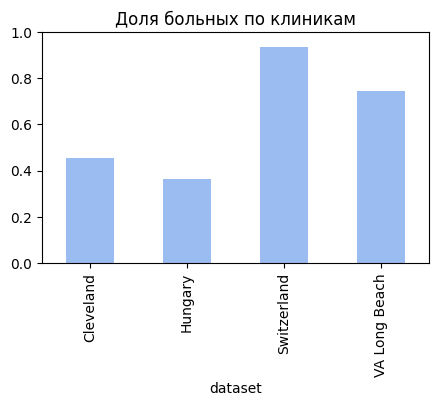

In [35]:
df["disease"] = (df.num > 0).astype(int)
prev = df.groupby('dataset').disease.agg(n='size', доля_больных='mean').round(3)
print(prev, '\n')
print("Общая доля больных:", df.disease.mean().round(3), "\n")
print(df.groupby("disease")[["age", "thalch", "oldpeak"]].mean().round(2))
print("\n")
print(pd.crosstab(df.exang, df.disease, normalize="index").round(2))

prev['доля_больных'].plot.bar(figsize=(5, 3), color='#9bbcf0', title='Доля больных по клиникам'); plt.ylim(0, 1); plt.show()

**Что видно:** **доля больных резко различается между клиниками**: Hungary 0.36, Cleveland 0.46, VA 0.75, Switzerland 0.93 — это разные популяции и/или правила направления на обследование. Поэтому `dataset` обязательно нужен модели (иначе клиника станет скрытым общим фактором). Метки корректны: у больных выше возраст (55.9 против 50.5), ниже пульс (128 против 149), выше `oldpeak` (1.3 против 0.4), а при `exang=True` доля больных 0.84 против 0.36.